# Cats vs Dogs: Image Classification with CNNs

**Goal:** classify photos as **Cat** or **Dog**. Compare a CNN trained from scratch, a regularized
CNN, and MobileNetV2 transfer learning. Explain predictions with Grad-CAM and serve the best
models in a Streamlit app.

**Dataset:** Microsoft PetImages, about 25k labelled photos, balanced
([Kaggle mirror](https://www.kaggle.com/datasets/shaunthesheep/microsoft-catsvsdogs-dataset)).

This notebook only orchestrates. The reusable code lives in `src/`
(`data.py`, `models.py`, `train.py`, ...). It runs locally or on Google Colab.

## 0. Setup

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
# Public GitHub repo, used only on Colab to fetch the code.
REPO_URL = "https://github.com/yashwanth-crypto/cats-vs-dogs-classifier.git"

if IN_COLAB:
    ROOT = Path("/content/cats-vs-dogs-classifier")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    os.chdir(ROOT)
    # Installs the exact TensorFlow/Keras pinned locally, so saved models load on both machines.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    os.chdir(ROOT)

sys.path.insert(0, str(ROOT))
print("Project root:", ROOT, "| Colab:", IN_COLAB)

Project root: C:\Image classifier | Colab: False


In [2]:
import tensorflow as tf, keras
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (CPU)")
expected = [l.strip().split("==")[1] for l in open("requirements.txt") if l.startswith(("tensorflow==", "keras=="))]
if [tf.__version__, keras.__version__] != expected:
    print(f"!! Versions differ from requirements.txt {expected}. On Colab: Runtime > Restart session, then run all again.")

TensorFlow 2.21.0 | Keras 3.15.1


GPU: none (CPU)


### Dataset
Local: download and extract the dataset into `data/` once. On Colab, the next cell downloads it
directly from Microsoft (about 790 MB, no Kaggle login needed).

In [3]:
from src.data import find_pet_images_dir

DATA_URL = ("https://download.microsoft.com/download/3/E/1/"
            "3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip")
try:
    IMAGE_DIR = find_pet_images_dir("data")
except FileNotFoundError:
    if not IN_COLAB:
        raise
    subprocess.run(["wget", "-q", "-O", "/content/pets.zip", DATA_URL], check=True)
    subprocess.run(["unzip", "-q", "-o", "/content/pets.zip", "-d", "data"], check=True)
    IMAGE_DIR = find_pet_images_dir("data")
print("Images in", IMAGE_DIR)

Images in data\kagglecatsanddogs_5340\PetImages


In [4]:
import pandas as pd
from src.data import SEED, load_split, make_dataset
from src.train import set_seed, train, verify

set_seed(SEED)
splits = {name: load_split(name) for name in ("train", "val", "test")}
pd.DataFrame({name: df["label"].value_counts() for name, df in splits.items()}).T.assign(
    total=lambda t: t.sum(axis=1)
)

label,cat,dog,total
train,8684,8655,17339
val,1860,1855,3715
test,1861,1854,3715


Splits come from `python -m src.data`. That step decoded all 25,002 files, dropped 233
(BMP/GIF/PNG/PSD files with a `.jpg` name, plus unreadable files), and made a stratified 70/15/15
split with seed 42. The split CSVs are committed, so every machine uses the same test set.

## Smoke test: one short end-to-end run
One epoch of the baseline CNN on a 1,000-image subset. It proves training, checkpointing and
reloading all work before any long run. `verify` reloads the saved file and checks it reproduces
the stored reference prediction.

In [5]:
from src.models import build_scratch_cnn

smoke_train = splits["train"].sample(1000, random_state=SEED)
smoke_val = splits["val"].sample(200, random_state=SEED)
smoke_model = build_scratch_cnn(img_size=128)
train(
    smoke_model,
    make_dataset(smoke_train, IMAGE_DIR, 128, shuffle=True),
    make_dataset(smoke_val, IMAGE_DIR, 128),
    name="smoke_baseline", epochs=1,
    reference_image=IMAGE_DIR / smoke_val["path"].iloc[0],
)
assert verify("models/smoke_baseline.keras", IMAGE_DIR)

32/32 - 8s - 237ms/step - accuracy: 0.5220 - auc: 0.5514 - loss: 0.6954 - val_accuracy: 0.4350 - val_auc: 0.6877 - val_loss: 0.6957 - learning_rate: 0.0010


smoke_baseline.keras: trained with TF 2.21.0 / Keras 3.15.1, loaded with TF 2.21.0 / Keras 3.15.1
  reference Dog/8250.jpg: saved p_dog=0.555513, now p_dog=0.555513 -> MATCH


## 1. Exploratory data analysis
Every figure is saved to `reports/figures/`.

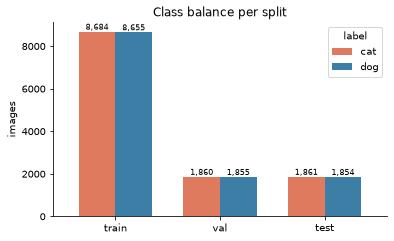

In [6]:
import matplotlib.pyplot as plt
from IPython import get_ipython
from src.viz import FIG_DIR, plot_class_balance, plot_sample_grid, image_sizes, plot_image_sizes

# Inline plots as compressed JPEG at screen resolution keep the notebook small enough to email.
# Full-quality PNGs are still saved to reports/figures/ (savefig uses its own dpi).
ipy = get_ipython()
ipy.run_line_magic("config", "InlineBackend.figure_formats = ['jpeg']")
ipy.run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'pil_kwargs': {'quality': 75}}")
plt.rcParams["figure.dpi"] = 72

plot_class_balance(splits, FIG_DIR / "class_balance.png"); plt.show()

The classes are balanced in every split (about 50/50), so accuracy is a fair headline metric.

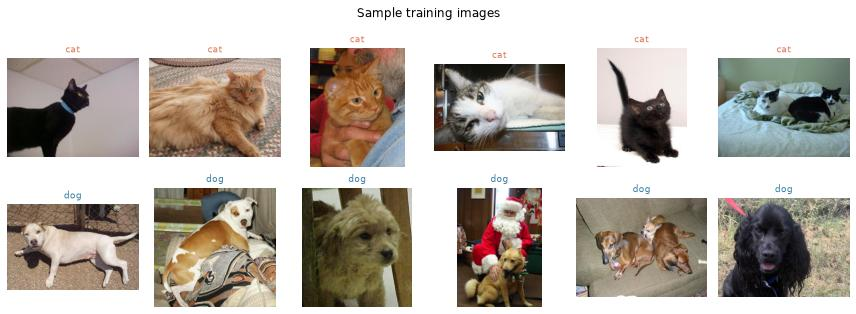

In [7]:
plot_sample_grid(splits["train"], IMAGE_DIR, save_to=FIG_DIR / "sample_grid.png"); plt.show()

The photos vary a lot: different poses, several animals in one frame, people, clutter and
indoor lighting. That's part of why the task is harder than it looks.

C:\Image classifier\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


,count,mean,std,min,25%,50%,75%,max
width,17339.0,405.0,108.0,50.0,325.0,448.0,500.0,500.0
height,17339.0,362.0,96.0,33.0,305.0,375.0,422.0,500.0


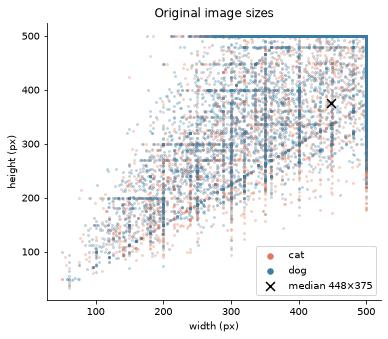

In [8]:
sized = image_sizes(splits["train"], IMAGE_DIR)
display(sized[["width", "height"]].describe().round(0).T)
plot_image_sizes(sized, FIG_DIR / "image_sizes.png"); plt.show()

Sizes vary (most are at most 500 px on the longer side, median about 448×375), so every image is resized to a
fixed square: 128×128 for the scratch CNNs and 160×160 for MobileNetV2. The aspect ratio isn't
kept, which slightly stretches some animals. That's an accepted trade-off for simplicity.

### Data augmentation (training set only)
Random horizontal flip, small rotation, zoom and brightness change. It's applied on the fly to
training batches, so every epoch sees slightly different images. Validation and test images are
never augmented.

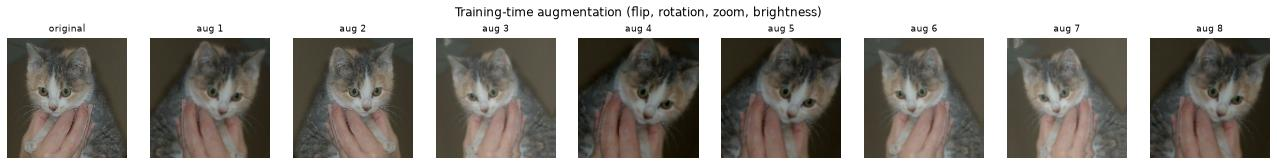

In [9]:
import numpy as np
from src.data import build_augmentation
from src.viz import plot_augmented

sample_img = tf.image.resize(
    tf.io.decode_jpeg(tf.io.read_file(str(IMAGE_DIR / splits["train"]["path"].iloc[3])), channels=3), (128, 128)
).numpy()
plot_augmented(sample_img, build_augmentation(), save_to=FIG_DIR / "augmented_samples.png"); plt.show()

## 2. Models
All three models are defined in `src/experiments.py` and trained with the same helper
(`src/train.py`): Adam, binary cross-entropy, and EarlyStopping / ModelCheckpoint /
ReduceLROnPlateau, all watching **validation** loss. Training only reads the train and val splits.

Set `RETRAIN = True` to train again. Otherwise the saved models and histories in `models/` are
loaded. They were trained locally on CPU with `python -m src.experiments <name>`, the same
function the next cells call.

In [10]:
import json
from src.experiments import run_experiment
from src.viz import plot_history

RETRAIN = False

def train_or_load(name):
    """Train the experiment if needed, then return its history and meta."""
    if RETRAIN or not Path(f"models/{name}.keras").exists():
        run_experiment(name, IMAGE_DIR)
    history = json.loads(Path(f"models/{name}_history.json").read_text())
    meta = json.loads(Path(f"models/{name}_meta.json").read_text())
    print(f"{name}: {meta['params']:,} params, {meta['epochs_run']} epochs, "
          f"{meta['train_seconds'] / 60:.1f} min, best epoch {meta['best_epoch']} "
          f"(val acc {meta['best_val_accuracy']:.3f})")
    return history, meta

### 2.1 Baseline CNN (from scratch, no augmentation)
3 × [Conv2D → ReLU → MaxPool] (32/64/128 filters) → Flatten → Dense(128) → Dropout(0.5) → sigmoid.
With no augmentation and no BatchNorm, we expect it to **overfit**: training accuracy keeps
rising while validation accuracy stalls.

baseline_cnn: 4,287,809 params, 10 epochs, 23.6 min, best epoch 5 (val acc 0.852)


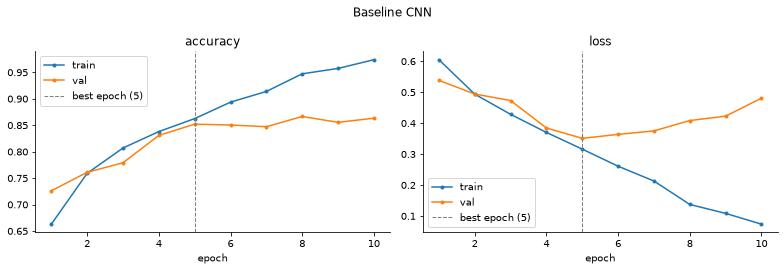

In [11]:
hist_base, meta_base = train_or_load("baseline_cnn")
plot_history(hist_base, "Baseline CNN", FIG_DIR / "curves_baseline_cnn.png"); plt.show()

### 2.2 Improved CNN (BatchNorm, Dropout, augmentation)
Same 3 conv blocks and filter counts. Changes: BatchNorm after every conv and after the Dense
layer, Dropout(0.1) after each block, training-time augmentation, and Adam at 3e-4.

**It took three runs to get right.** That's worth knowing, because "add regularization" isn't free:
1. *BatchNorm + Dropout(0.2) per block, lr 1e-3:* **83.3% val, worse than the baseline.** It
   underfit (train accuracy about 66%).
2. Diagnosis: without the per-block dropout the model got stuck predicting one class (50%). The
   BatchNorm-scaled 32,768 flattened features blew up the 4.2M-weight Dense layer at lr 1e-3,
   and its ReLUs died. This happened on both the TensorFlow and PyTorch backends. *Fix:* BatchNorm
   after the Dense layer too, BN momentum 0.9 so the running statistics keep up, and lr 3e-4.
   Result: 85.3%. It trained, but the learning-rate scheduler (patience 2) halved the rate 5 times
   on the noisy validation curve and stalled it.
3. *Same model, more patient schedule (LR patience 4, early-stopping patience 12):* the final
   model below.

improved_cnn: 4,288,865 params, 26 epochs, 21.6 min, best epoch 14 (val acc 0.868)


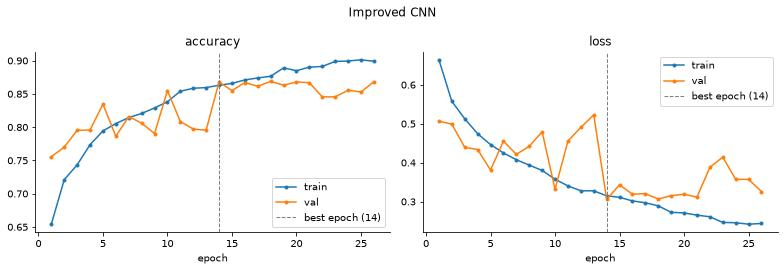

In [12]:
hist_imp, meta_imp = train_or_load("improved_cnn")
plot_history(hist_imp, "Improved CNN", FIG_DIR / "curves_improved_cnn.png"); plt.show()

### 2.3 MobileNetV2 (transfer learning)
ImageNet-pretrained MobileNetV2 at 160×160. Preprocessing to [-1, 1] is a layer inside the model.
**Stage 1:** base frozen, train only the new head (GlobalAveragePooling → Dropout(0.2) → sigmoid).
**Stage 2 (shaded):** unfreeze the top 30 base layers (BatchNorm stays frozen) and fine-tune at lr 1e-5.

mobilenetv2: 2,259,265 params, 17 epochs, 23.7 min, best epoch 15 (val acc 0.989)


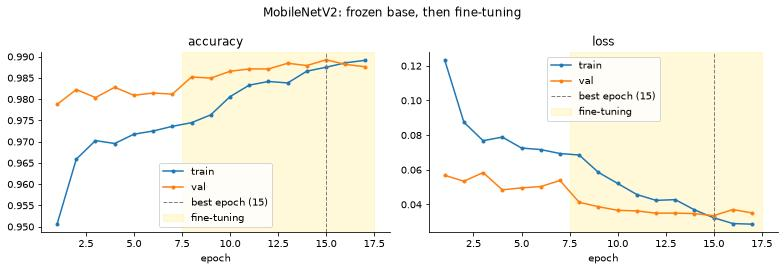

In [13]:
hist_mnv2, meta_mnv2 = train_or_load("mobilenetv2")
plot_history(hist_mnv2, "MobileNetV2: frozen base, then fine-tuning", FIG_DIR / "curves_mobilenetv2.png",
             stage_boundary=meta_mnv2.get("fine_tune_from_epoch")); plt.show()

**Reading the curves together:**
- **Baseline:** train accuracy climbs to 97% while validation flattens around 85%. Classic overfitting.
  Early stopping keeps the epoch-5 weights.
- **Improved CNN:** train and validation stay within a few points of each other. Regularization
  closed the generalization gap, and validation loss is lower than the baseline's. The validation
  curve is noisy because BatchNorm statistics drift while augmentation keeps the inputs changing.
- **MobileNetV2:** starts at about 98% val after a single epoch. Features learned on 1.2M ImageNet
  photos transfer almost perfectly, and fine-tuning adds the last fraction of a percent.

## 3. Evaluation on the held-out test set
This is the **first time the test split is used**: 3,715 images that no model or tuning decision
has seen. Positive class = dog.

In [14]:
import keras
from src.evaluate import (comparison_table, compute_metrics, plot_confusion_matrix, plot_roc_curves,
                          plot_error_grid, predict_split, top_confident_errors)

MODEL_NAMES = ["baseline_cnn", "improved_cnn", "mobilenetv2"]
test_df = splits["test"]
y_test = test_df["label_id"].to_numpy()

models, metas, probs, results = {}, {}, {}, {}
for name in MODEL_NAMES:
    models[name] = keras.models.load_model(f"models/{name}.keras", compile=False)
    metas[name] = json.loads(Path(f"models/{name}_meta.json").read_text())
    test_ds = make_dataset(test_df, IMAGE_DIR, metas[name]["img_size"], batch_size=64)
    probs[name] = predict_split(models[name], test_ds)
    results[name] = compute_metrics(y_test, probs[name])

table = comparison_table(results, metas)
Path("reports").mkdir(exist_ok=True)
table.to_csv("reports/comparison_table.csv")
table

,params,trainable_params,input,accuracy,precision,recall,f1,roc_auc,epochs,train_min,trained_on
model,,,,,,,,,,,
baseline_cnn,4287809,4287809,128×128,0.8458,0.8362,0.8592,0.8476,0.9185,10,23.6,CPU
improved_cnn,4288865,4288161,128×128,0.8573,0.8548,0.8603,0.8575,0.9341,26,21.6,GPU (RTX 5060)
mobilenetv2,2259265,1512001,160×160,0.9892,0.9882,0.9903,0.9892,0.9992,17,23.7,GPU (RTX 5060)


In [15]:
# Markdown version of the table for the README and the report.
md_lines = ["| " + " | ".join(["model", *table.columns]) + " |", "|" + "---|" * (len(table.columns) + 1)]
for name, row in table.iterrows():
    md_lines.append("| " + " | ".join([name, *[f"{v:,}" if isinstance(v, (int, np.integer)) else str(v) for v in row]]) + " |")
Path("reports/comparison_table.md").write_text("\n".join(md_lines) + "\n", encoding="utf-8")
print("\n".join(md_lines))

| model | params | trainable_params | input | accuracy | precision | recall | f1 | roc_auc | epochs | train_min | trained_on |
|---|---|---|---|---|---|---|---|---|---|---|---|
| baseline_cnn | 4,287,809 | 4,287,809 | 128×128 | 0.8458 | 0.8362 | 0.8592 | 0.8476 | 0.9185 | 10 | 23.6 | CPU |
| improved_cnn | 4,288,865 | 4,288,161 | 128×128 | 0.8573 | 0.8548 | 0.8603 | 0.8575 | 0.9341 | 26 | 21.6 | GPU (RTX 5060) |
| mobilenetv2 | 2,259,265 | 1,512,001 | 160×160 | 0.9892 | 0.9882 | 0.9903 | 0.9892 | 0.9992 | 17 | 23.7 | GPU (RTX 5060) |


### Confusion matrices and ROC curves

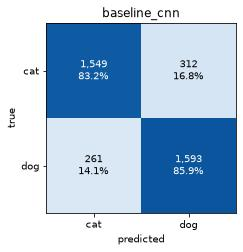

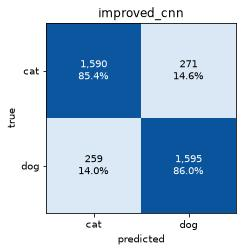

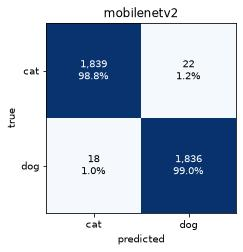

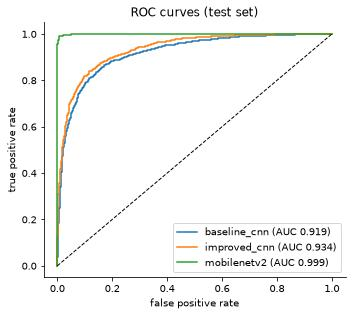

In [16]:
for name in MODEL_NAMES:
    plot_confusion_matrix(y_test, probs[name], name, save_to=FIG_DIR / f"cm_{name}.png")
plt.show()
plot_roc_curves(y_test, probs, save_to=FIG_DIR / "roc_curves.png"); plt.show()

## 4. Error analysis
The test images each model got wrong **with the highest confidence**. These are the most
informative failures. Each title gives the test-set index, the true label, and the prediction
with its confidence.

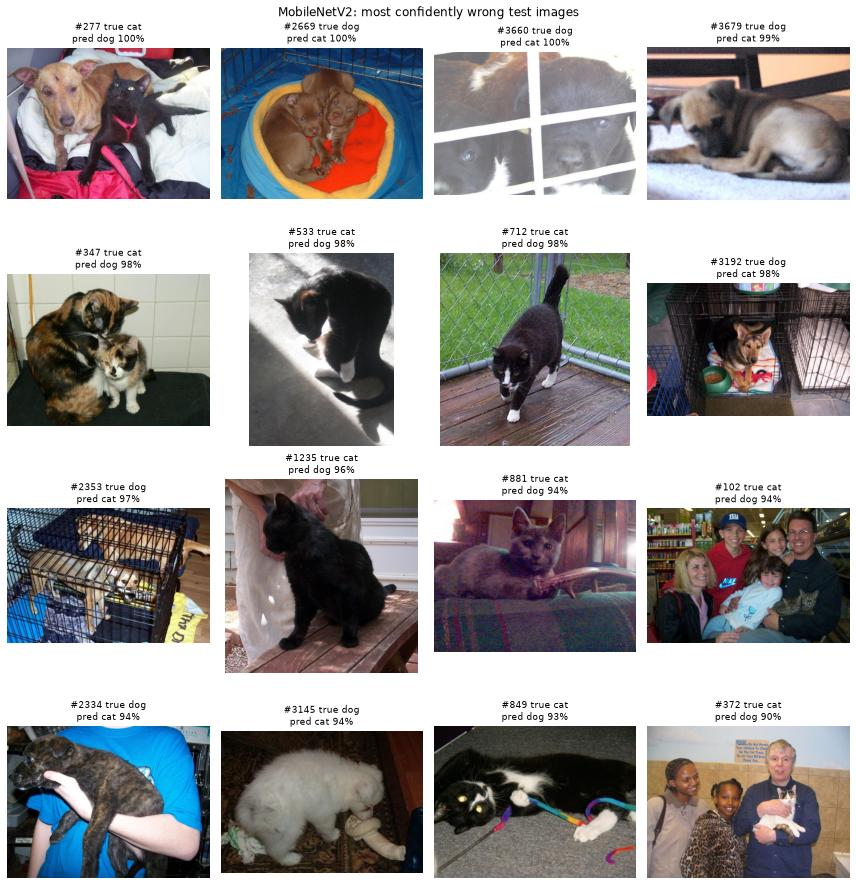

In [17]:
errors = {name: top_confident_errors(test_df, probs[name], k=16) for name in ["mobilenetv2", "improved_cnn"]}
plot_error_grid(errors["mobilenetv2"], IMAGE_DIR, "MobileNetV2: most confidently wrong test images",
                save_to=FIG_DIR / "errors_mobilenetv2.png"); plt.show()

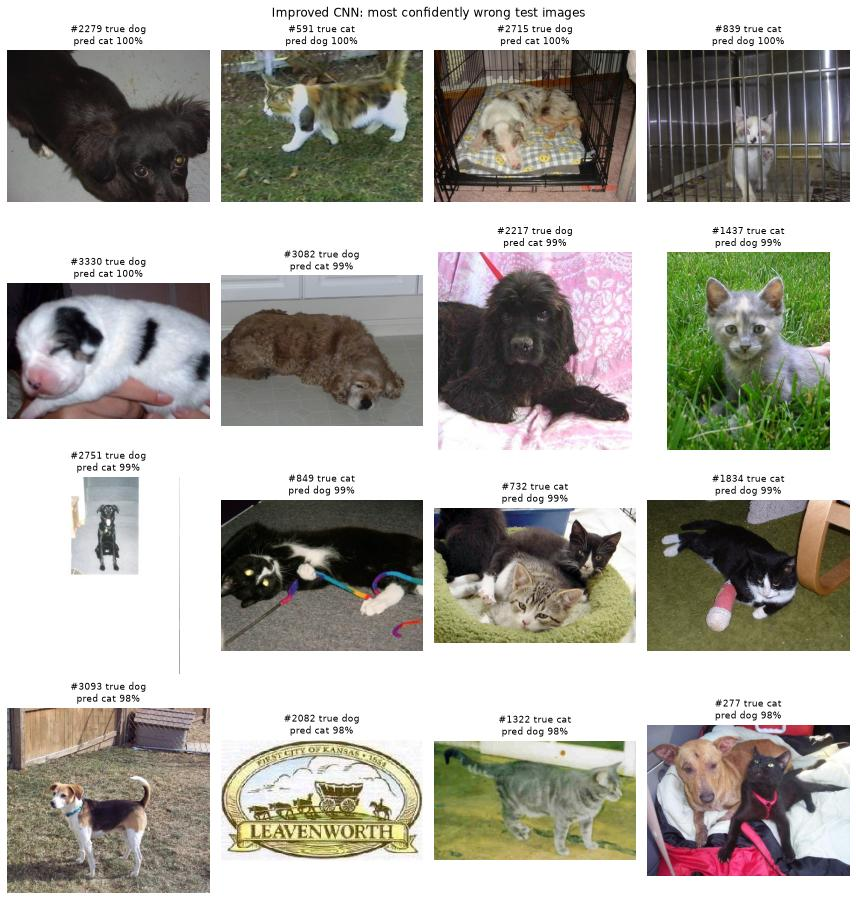

In [18]:
plot_error_grid(errors["improved_cnn"], IMAGE_DIR, "Improved CNN: most confidently wrong test images",
                save_to=FIG_DIR / "errors_improved_cnn.png"); plt.show()

**Failure patterns** (test-set indices from the grids above):

1. **Both species, or label noise.** #277 is labelled *cat* but shows a dog and a cat side by
   side. MobileNetV2 says *dog* with 100% confidence, and Grad-CAM (below) shows it looking at the
   dog, so arguably it's right. #2082 is labelled *dog* but is a **Leavenworth town logo** with no
   animal at all. Some "errors" are dataset problems, and the true error rate is a little lower.
2. **Puppies and curled-up poses.** #2669 (two puppies curled in a bed), #3679 and #2334 (puppies
   lying down or held), and #3145 (a white fluffy dog) are called *cat*. Round, small, curled shapes
   without a visible snout look cat-like.
3. **Occlusion and cages.** #3660 (puppies behind window bars, overexposed), #3192 and #2353
   (dogs inside crates). The bars break up the animal's outline.
4. **Face hidden, dark fur, harsh light.** #533 (black cat in strong sunlight, head down), #1235
   (black cat, face turned away), #347 (two cats, heads down). Black animals lose the facial
   detail that separates the classes.
5. **Small animal, busy scene.** #102 and #372: families in a pet shop holding a small cat. People
   take up most of the frame.

The improved CNN fails in the same places, plus easier ones: well-lit, clearly visible cats on
grass (#591, #1437) and a beagle in a yard (#3093). It hasn't learned robust animal features. The
Grad-CAM comparison below shows why.

## 5. Grad-CAM: what is the model looking at?
Grad-CAM weights the last convolutional feature maps by the gradient of the predicted class's
score, which highlights the regions that pushed the model toward its answer. It's shown for
MobileNetV2 (the deployed model) on random correct test predictions and on its confident mistakes.

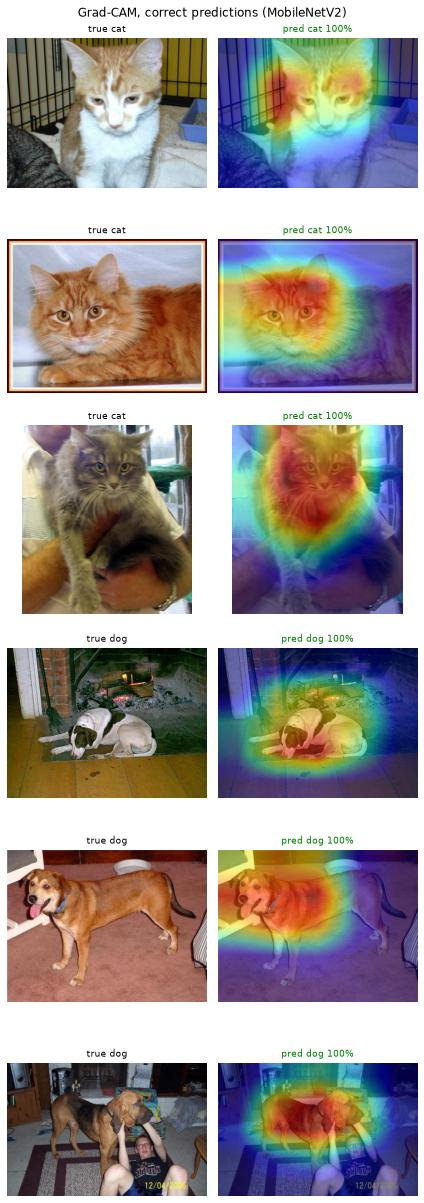

In [19]:
from src.viz import plot_gradcam_grid

scored = test_df.assign(p_dog=probs["mobilenetv2"])
scored["pred_label"] = np.where(scored["p_dog"] >= 0.5, "dog", "cat")
scored["confidence"] = np.where(scored["p_dog"] >= 0.5, scored["p_dog"], 1 - scored["p_dog"])
correct = pd.concat([scored[(scored.label == c) & (scored.pred_label == c)].sample(3, random_state=SEED)
                     for c in ("cat", "dog")])
plot_gradcam_grid(correct, IMAGE_DIR, models["mobilenetv2"], metas["mobilenetv2"],
                  "Grad-CAM, correct predictions (MobileNetV2)", FIG_DIR / "gradcam_correct.png"); plt.show()

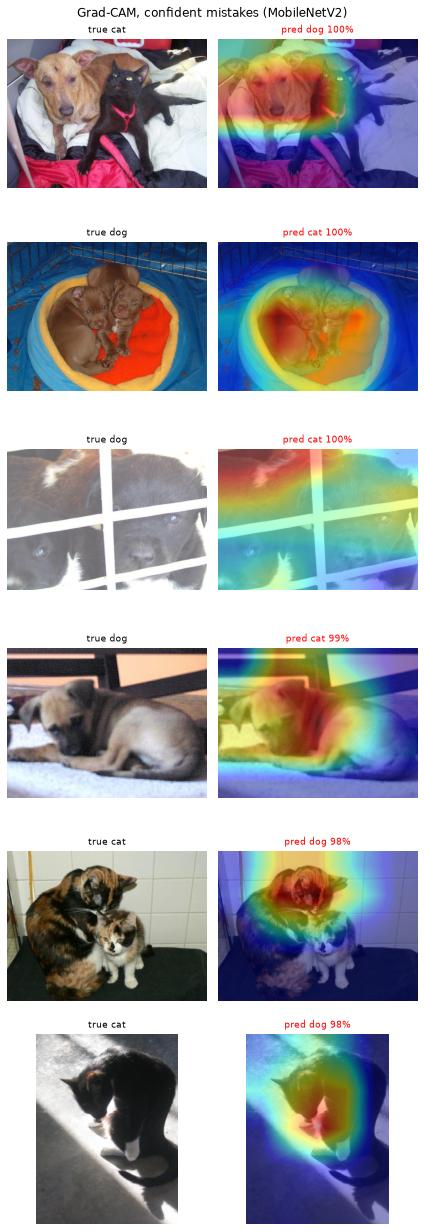

In [20]:
plot_gradcam_grid(errors["mobilenetv2"].head(6), IMAGE_DIR, models["mobilenetv2"], metas["mobilenetv2"],
                  "Grad-CAM, confident mistakes (MobileNetV2)", FIG_DIR / "gradcam_incorrect.png"); plt.show()

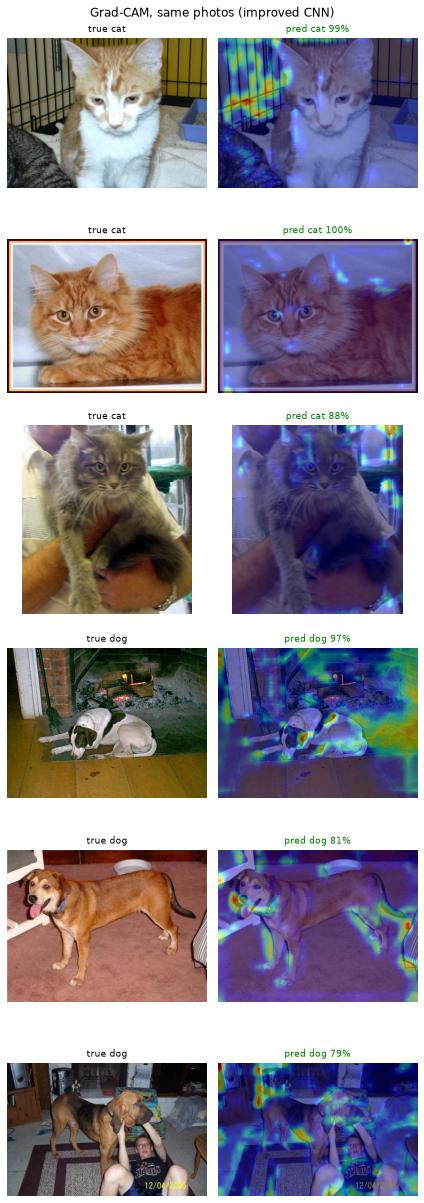

In [21]:
# Same photos, scratch-built improved CNN: does a weaker model look at the same things?
plot_gradcam_grid(correct.assign(**{"pred_label": np.where(probs["improved_cnn"][correct.index] >= 0.5, "dog", "cat"),
                                    "confidence": np.maximum(probs["improved_cnn"][correct.index],
                                                             1 - probs["improved_cnn"][correct.index])}),
                  IMAGE_DIR, models["improved_cnn"], metas["improved_cnn"],
                  "Grad-CAM, same photos (improved CNN)", FIG_DIR / "gradcam_improved_cnn.png"); plt.show()

**What Grad-CAM shows:**
- **MobileNetV2 looks at the animal.** On correct predictions the heat sits on the head and body.
  On mistakes it still looks at the animal but picks the wrong evidence. On #277 it highlights the
  *dog* in a photo labelled *cat*. On the curled puppies it covers both bodies, which do look
  cat-like.
- **The scratch-built improved CNN often looks at the background**: cage bars, picture frames,
  carpet edges and room clutter, with only scattered spots on the animal. It reaches 86% partly
  through **shortcut features** that happen to correlate with the label (cats are photographed
  more often indoors and in cages here), not by recognizing cats and dogs. That explains why it
  fails on easy photos, and why accuracy alone overstates what it learned.
- That's the strongest argument for transfer learning on a dataset of this size: ImageNet
  pretraining gives the network real object features, so it has no need for shortcuts.

In [22]:
# Colab only: copy saved models to Google Drive so they can be downloaded into models/ locally.
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    dest = Path("/content/drive/MyDrive/cats-vs-dogs-models")
    dest.mkdir(parents=True, exist_ok=True)
    subprocess.run(f"cp models/*.keras models/*.json {dest}/", shell=True, check=True)
    print("Copied to", dest)